##### Copyright 2022 The TensorFlow Compression Authors.

In [2]:
#@title Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
# https://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

# Learned data compression

<table class="tfo-notebook-buttons" align="left">
  <td>
    <a target="_blank" href="https://www.tensorflow.org/tutorials/generative/data_compression">
    <img src="https://www.tensorflow.org/images/tf_logo_32px.png" />
    View on TensorFlow.org</a>
  </td>
  <td>
    <a target="_blank" href="https://colab.research.google.com/github/tensorflow/docs/blob/master/site/en/tutorials/generative/data_compression.ipynb">
    <img src="https://www.tensorflow.org/images/colab_logo_32px.png" />
    Run in Google Colab</a>
  </td>
  <td>
    <a target="_blank" href="https://github.com/tensorflow/docs/blob/master/site/en/tutorials/generative/data_compression.ipynb">
    <img src="https://www.tensorflow.org/images/GitHub-Mark-32px.png" />
    View source on GitHub</a>
  </td>
  <td>
    <a href="https://storage.googleapis.com/tensorflow_docs/docs/site/en/tutorials/generative/data_compression.ipynb"><img src="https://www.tensorflow.org/images/download_logo_32px.png" />Download notebook</a>
  </td>
</table>

## Overview

This notebook shows how to do lossy data compression using neural networks and [TensorFlow Compression](https://github.com/tensorflow/compression).

Lossy compression involves making a trade-off between **rate**, the expected number of bits needed to encode a sample, and **distortion**, the expected error in the reconstruction of the sample.

The examples below use an autoencoder-like model to compress images from the MNIST dataset. The method is based on the paper [End-to-end Optimized Image Compression](https://arxiv.org/abs/1611.01704).

More background on learned data compression can be found in [this paper](https://arxiv.org/abs/2007.03034) targeted at people familiar with classical data compression, or [this survey](https://arxiv.org/abs/2202.06533) targeted at a machine learning audience.


## Setup

Install Tensorflow Compression via `pip`.

In [3]:
# %%bash
# # Installs the latest version of TFC compatible with the installed TF version.

# read MAJOR MINOR <<< "$(pip show tensorflow | perl -p -0777 -e 's/.*Version: (\d+)\.(\d+).*/\1 \2/sg')"
# pip install "tensorflow-compression<$MAJOR.$(($MINOR+1))"


Import library dependencies.

In [4]:
import tensorrt
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_compression as tfc
import tensorflow_datasets as tfds

2023-11-15 22:38:46.843963: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [5]:
!printenv | grep XLA

XLA_FLAGS=--xla_gpu_cuda_data_dir=/usr/lib/cuda/


Correct error for GPU memory usage and check if the GPU is available

In [6]:
physical_devices = tf.config.list_physical_devices('GPU')
print(physical_devices)

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


2023-11-15 21:57:43.266961: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:995] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2023-11-15 21:57:43.445567: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:995] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2023-11-15 21:57:43.445838: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:995] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysf

In [7]:
# Set GPU memory limit
tf.config.experimental.set_memory_growth(physical_devices[0], True)

## Define the trainer model.

Because the model resembles an autoencoder, and we need to perform a different set of functions during training and inference, the setup is a little different from, say, a classifier.

The training model consists of three parts:
- the **analysis** (or encoder) transform, converting from the image into a latent space,
- the **synthesis** (or decoder) transform, converting from the latent space back into image space, and
- a **prior** and entropy model, modeling the marginal probabilities of the latents.

First, define the transforms:

In [8]:
# the encoder(analysis transform) is a NN with 4 layers: two 2D CONV layers and 2 FC layers! 
# The 1st convolutional layer has: 
# - 20 filters (the dimensionality of the output space (i.e. the number of output filters in the convolution)
# - kernel size of 5 (height and width of the 2D convolution window)
# - 2 strides (specifying the strides of the convolution along the height and width, the step size of the convolution window!)
# - padding:"same" results in padding with zeros evenly to the left/right or up/down of the input
# - If use_bias is True, a bias vector is created and added to the outputs

# The 2nd convolutional layer is very similar to the 1st but the spectral dimension increases (output features are smaller but are more)

# We end up with 50 features that are vectorized: small images are converted to vectors (flattened)

# Now, a 2 layers fully connected network is used to find the optimal regression function!

# Every image is converted in a vector (code) in the latent space! The dimension of the vector is related to the rate/distortion tradeoff (I guess...)

def make_analysis_transform(latent_dims):
  """Creates the analysis (encoder) transform."""
  return tf.keras.Sequential([
            
            # 1st conv layer
            tf.keras.layers.Conv2D(
                20, 
                5, 
                use_bias = True, 
                strides=2, 
                padding="same",
                activation="leaky_relu",
                name="conv_1"),
            
            # 2nd conv layer
            tf.keras.layers.Conv2D(
                50, 
                5,
                use_bias = True,
                strides=2, 
                padding="same",
                activation="leaky_relu",
                name="conv_2"),
            
            tf.keras.layers.Flatten(),
            
            tf.keras.layers.Dense(
                500, 
                use_bias = True,
                activation="leaky_relu", 
                name="fc_1"),
            
            tf.keras.layers.Dense(
                latent_dims,
                use_bias = True,
                activation = None,
                name="fc_2"),
            ], 
            name="analysis_transform")


In [9]:
# The decoder (synthesis transform) is a NN that converst codes (vectors in the latent space) into images! 
# This is done using a 2 layers fully connected network to learn the optimal feature to retrieve the original images, 
# and that applying a 2 layers 2D convolutional netowrk to retrieve the images.

def make_synthesis_transform():
  """Creates the synthesis (decoder) transform."""
  return tf.keras.Sequential([
      
            tf.keras.layers.Dense(
                500, 
                use_bias=True,
                activation="leaky_relu",
                name="fc_1"),
            
            tf.keras.layers.Dense(
                2450,
                use_bias=True,
                activation="leaky_relu",
                name="fc_2"),
            
            tf.keras.layers.Reshape((7, 7, 50)),
            
            tf.keras.layers.Conv2DTranspose(
                20, 
                5, 
                use_bias=True, 
                strides=2, 
                padding="same",
                activation="leaky_relu", 
                name="conv_1"),
            
            tf.keras.layers.Conv2DTranspose(
                1,
                5,
                use_bias=True,
                strides=2, 
                padding="same",
                activation="leaky_relu", 
                name="conv_2"),
        
            ], name="synthesis_transform")


The trainer holds an instance of both transforms, as well as the parameters of the prior.

Its `call` method is set up to compute:
- **rate**, an estimate of the number of bits needed to represent the batch of digits, and
- **distortion**, the mean absolute difference between the pixels of the original digits and their reconstructions.


In [10]:
# Trainter object, we use this class for the training + computation of rate and distortion
# There are 3 methods:
# - constructor: creates analysis, synthesis and creates the scales according to the number of latent dimensions
# - prior: builds the prior
# - call: given an x, computes the rate and the distortion

# Trainer object
class CompressionTrainer(tf.keras.Model):
  """Model that trains a compressor/decompressor for MNIST."""

  # Constructor
  def __init__(self, latent_dims):
    super().__init__()
    
    # Set analysis and synthesis NNs (build the NNs structures)
    self.analysis_transform = make_analysis_transform(latent_dims)
    self.synthesis_transform = make_synthesis_transform()
    
    # This should be the standard deviations of the latent dimensions of the latent vectors. The 10 std define the multimodal distribution of the latent vectors
    # Create the prior_log_scales variable (array of 10 zeros that will change with learning, I guess...)
    # the fact that they are defined logarithmic is just a convention
    self.prior_log_scales = tf.Variable(tf.zeros((latent_dims,))) 
    # The Variable() constructor requires an initial value for the variable, which can be a Tensor of any type and shape. 
    # This initial value defines the type and shape of the variable. After construction, the type and shape of the variable are fixed. 
    # The value can be changed using one of the assign methods.


  # The prior is initialized, nothing special: it uses the scales defined above (10 scales in this case)
  # property decorator: this is Python's way of creating getters, setters, and deleters (or mutator methods) for a property in a class.
  @property
  def prior(self):
    # NoisyLogistic: logistic distribution with additive i.i.d. uniform noise.
    return tfc.NoisyLogistic(loc=0., scale=tf.exp(self.prior_log_scales))


  # Call method sets up and compute the rate and the distortion
  def call(self, x, training):
    """Computes rate and distortion losses for a single image x."""
    # --training-- is a parameter that controls how the rate is computed (during training adding additive noise, during validation/testing with quantization)
    
    # Ensure inputs are floats in the range (0, 1).
    x = tf.cast(x, self.compute_dtype) / 255.
    # Add a batch dimension (28x28 are the spatial dimensions of the input image)
    x = tf.reshape(x, (-1, 28, 28, 1))

    # Compute latent space representation y, perturb it (additive noise during trainign or quantization during validation/testing),
    # then compute the reconstructed pixel-level representation x_hat.
    y = self.analysis_transform(x)
    entropy_model = tfc.ContinuousBatchedEntropyModel(self.prior, coding_rank=1, compression=False)
    y_tilde, rate = entropy_model(y, training=training)  
    x_tilde = self.synthesis_transform(y_tilde)

    # Average number of bits per MNIST digit.
    rate = tf.reduce_mean(rate) # reduce_mean computes the mean across the dimensions of the tensor, here (10,) 

    # Mean absolute difference across pixels.
    distortion = tf.reduce_mean(abs(x - x_tilde)) # distortion computed as MAE (not MSE)

    # returns all the rate/distortion pairs
    return dict(rate=rate, distortion=distortion)


### Loading datasets

In [1]:
# Loads the data to use (low resolution cat images)

training_dataset, validation_dataset = tfds.load(
    "cifar10",
    split=["train", "test"],
    shuffle_files=True,
    as_supervised=True,
    with_info=False,
)

In [12]:
# Keeps only cat images
# lcat_training_dataset = lcat_training_dataset.filter(lambda X, y: y == 3)
# lcat_validation_dataset = lcat_validation_dataset.filter(lambda label: label == 3)


In [13]:
# lcat_training_dataset.cardinality().numpy() # [-2: undeterminated cardinality]

# Try to print the first elements to check the value and class
# # Assuming `my_dataset` is your dataset
# my_dataset = lcat_training_dataset  # Replace ... with your actual dataset
#
# # Convert to a numpy iterator
# dataset_iterator = iter(my_dataset.as_numpy_iterator())
#
# # Iterate through the dataset and print the elements
# i = 0
# for element in dataset_iterator:
#     i=i+1 
#     print(element[1]) # element[1] is the label
#     if i == 10:
#         break

In [16]:
# print("Number of training examples of Low Res CATS:", lcat_training_dataset.cardinality())
# print("Number of testing examples of Low Res CATS:", lcat_validation_dataset.cardinality())

Number of training examples of High Res CATS: 72
Number of testing examples of High Res CATS: 33


In [18]:
import cv2 

# training dataset preparation
training_data = tf.convert_to_tensor(temp, dtype=tf.uint8)[:,:,:,None]
training_data = tf.data.Dataset.from_tensor_slices(training_data)

# testing dataset preparation
validation_data = tf.convert_to_tensor(temp, dtype=tf.uint8)[:,:,:,None]
validation_data = tf.data.Dataset.from_tensor_slices(validation_data)

print('Training size:', training_dataset.cardinality)
print('Validation size:', validation_dataset.cardinality)

Training size: <bound method DatasetV2.cardinality of <_ZipDataset element_spec=(TensorSpec(shape=(28, 28, 1), dtype=tf.uint8, name=None), TensorSpec(shape=(), dtype=tf.float32, name=None))>>
Validation size: <bound method DatasetV2.cardinality of <_ZipDataset element_spec=(TensorSpec(shape=(28, 28, 1), dtype=tf.uint8, name=None), TensorSpec(shape=(), dtype=tf.float32, name=None))>>


### Extract one image $x$:

Data type: <dtype: 'uint8'>
Shape: (28, 28, 1)


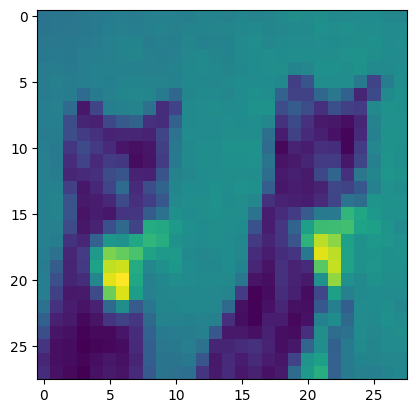

In [19]:
# Take one image from the dataset and observe it
(x,_), = validation_dataset.take(1)

plt.imshow(tf.squeeze(x))
print(f"Data type: {x.dtype}")
print(f"Shape: {x.shape}")

## Train the model

We compile the trainer in a way that it optimizes the rate–distortion Lagrangian, that is, a sum of rate and distortion, where one of the terms is weighted by Lagrange parameter $\lambda$.

This loss function affects the different parts of the model differently:
- The analysis transform is trained to produce a latent representation that achieves the desired trade-off between rate and distortion.
- The synthesis transform is trained to minimize distortion, given the latent representation.
- The parameters of the prior are trained to minimize the rate given the latent representation. This is identical to fitting the prior to the marginal distribution of latents in a maximum likelihood sense.

In [20]:
# hyperparameters
LATENT_DIM = 10
LEARNING_RATE = 1e-3

# UNSUPERVISED LEARNING! 
def pass_through_loss(_, x):
  # Since rate and distortion are unsupervised, the loss doesn't need a target.
  return x


# TRAINER INSTANTIATION AND INITIALIZATION
# function that initializes the trainer with:
# - a given latent dimension
# - a given lamba(rate/distorition trade off)
def make_compression_trainer(lmbda, latent_dims=LATENT_DIM):
  # create trainer object (constructor is executed!)
  trainer = CompressionTrainer(latent_dims)
  # setting training parameters
  trainer.compile(
    # set training algorithm (Adam with the learning rate)
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    # define loss function for training (just pass through rate and distortion as losses/metrics)
    loss = dict(rate=pass_through_loss, distortion=pass_through_loss),
    metrics = dict(rate=pass_through_loss, distortion=pass_through_loss),
    loss_weights = dict(rate=1., distortion=lmbda),
  )
  return trainer


Next, train the model. The human annotations are not necessary here, since we just want to compress the images, so we drop them using a `map` and instead add "dummy" targets for rate and distortion.

In [60]:
# Define "dummy" labels
def add_rd_targets(image, label):
  # Training is unsupervised, so labels aren't necessary here. However, we
  # need to add "dummy" targets for rate and distortion.
  return image, dict(rate=0., distortion=0.)


# TRAINING (given a lambda)
def train_model(lmbda):
  
  # create trainer, define training algorithm and loss function to optimize
  trainer = make_compression_trainer(lmbda)

  # Perform training
  trainer.fit(
      # take training batch
      training_dataset.map(add_rd_targets).batch(128).prefetch(8),
      epochs=2000,
      # take validation batch
      validation_data=validation_dataset.map(add_rd_targets).batch(128).cache(),
      validation_freq=1,
      verbose=1,
  )
  return trainer

# Finally train the model with given lambda
trainer = train_model(lmbda=100)


Epoch 1/2000
1/1 [==============================] - ETA: 0s - loss: 61.2871 - distortion_loss: 0.4071 - rate_loss: 20.5806 - distortion_pass_through_loss: 0.4071 - rate_pass_through_loss: 20.5806

1/1 [==============================] - 11s 11s/step - loss: 61.2871 - distortion_loss: 0.4071 - rate_loss: 20.5806 - distortion_pass_through_loss: 0.4071 - rate_pass_through_loss: 20.5806 - val_loss: 64.2869 - val_distortion_loss: 0.4381 - val_rate_loss: 20.4815 - val_distortion_pass_through_loss: 0.4381 - val_rate_pass_through_loss: 20.4815
Epoch 2/2000
1/1 [==============================] - 0s 78ms/step - loss: 60.8075 - distortion_loss: 0.4010 - rate_loss: 20.7080 - distortion_pass_through_loss: 0.4010 - rate_pass_through_loss: 20.7080 - val_loss: 64.0938 - val_distortion_loss: 0.4383 - val_rate_loss: 20.2686 - val_distortion_pass_through_loss: 0.4383 - val_rate_pass_through_loss: 20.2686
Epoch 3/2000
1/1 [==============================] - 0s 86ms/step - loss: 60.0259 - distortion_loss: 0.3940 - rate_loss: 20.6239 - distortion_pass_through_loss: 0.3940 - rate_pass_through_loss: 20.6239 - val_loss: 61.8924 - val_distortion_loss: 0.4112 - val_rate_loss: 20.7744 - val_distortion_pass_t

## Compress some images.

For compression and decompression at test time, we split the trained model in two parts:

- The encoder side consists of the analysis transform and the entropy model.
- The decoder side consists of the synthesis transform and the same entropy model.

At test time, the latents will not have additive noise, but they will be quantized and then losslessly compressed, so we give them new names. We call them and the image reconstruction $\hat x$ and $\hat y$, respectively (following [End-to-end Optimized Image Compression](https://arxiv.org/abs/1611.01704)).

In [61]:
# class of the COMPRESSION MODEL (trained model)
# methods:
# - constructor: uses the leart analysis (transform learnt to max the rate and min the dist) and entropy model (distribution of the latent learnt to max the rate)
# - call: given an image x it compresses it and encodes it + it computes the rate using entropy_model with training=False (quantization) 

class Compressor(tf.keras.Model):
  """Compresses MNIST images to strings."""

  # constructor
  def __init__(self, analysis_transform, entropy_model):
    super().__init__()
    # analysis here is optimal after training
    self.analysis_transform = analysis_transform
    # entropy model is optimal after training
    self.entropy_model = entropy_model

  def call(self, x):

    # Ensure inputs are floats in the range (0, 1).
    x = tf.cast(x, self.compute_dtype) / 255.
    
    # actual compression
    y = self.analysis_transform(x)

    # Also return the exact information content of each digit.
    _, bits = self.entropy_model(y, training=False)
    
    return self.entropy_model.compress(y), bits


In [62]:
# class of the DECOMPRESSION MODEL (trained model)
# methods:
# - constructor: uses the learnt synthesis (transform learnt to min the dist) and entropy model (distribution of the latent learnt to max the rate)
# - call: given a string it decodes it + decompresses it

class Decompressor(tf.keras.Model):
  """Decompresses MNIST images from strings."""

  def __init__(self, entropy_model, synthesis_transform):
    super().__init__()
    self.entropy_model = entropy_model
    self.synthesis_transform = synthesis_transform

  def call(self, string):
    # decode the vector in the latent space
    y_hat = self.entropy_model.decompress(string, ())
    # reconstruct the image from the vector
    x_hat = self.synthesis_transform(y_hat)
    
    # Scale and cast back to 8-bit integer.
    return tf.saturate_cast(tf.round(x_hat * 255.), tf.uint8)


When instantiated with `compression=True`, the entropy model converts the learned prior into tables for a range coding algorithm. When calling `compress()`, this algorithm is invoked to convert the latent space vector into bit sequences. The length of each binary string approximates the information content of the latent (the negative log likelihood of the latent under the prior).

The entropy model for compression and decompression must be the same instance, because the range coding tables need to be exactly identical on both sides. Otherwise, decoding errors can occur.

In [63]:
def make_codec(trainer, **kwargs):
  # The entropy model must be created with `compression=True` and the same
  # instance must be shared between compressor and decompressor.
  entropy_model = tfc.ContinuousBatchedEntropyModel(
      trainer.prior, coding_rank=1, compression=True, **kwargs)
  compressor = Compressor(trainer.analysis_transform, entropy_model)
  decompressor = Decompressor(entropy_model, trainer.synthesis_transform)
  return compressor, decompressor

compressor, decompressor = make_codec(trainer)


Grab 16 images from the validation dataset. You can select a different subset by changing the argument to `skip`.

In [64]:
(originals, _), = validation_dataset.batch(16).skip(2).take(1)

originals.shape

TensorShape([1, 28, 28, 1])

In [65]:
import cv2

# HIGH RES CATS
originals = hcat_train_class_images[:16]

originals = [cv2.resize(x, (28, 28), interpolation=cv2.INTER_AREA) for x in originals]
originals = [cv2.cvtColor(x, cv2.COLOR_BGR2GRAY) for x in originals]

originals = tf.convert_to_tensor(originals, dtype=tf.uint8)
originals[:,:,:,None].shape

TensorShape([16, 28, 28, 1])

Compress them to strings, and keep track of each of their information content in bits.

In [66]:
strings, entropies = compressor(originals)

print(f"String representation of first digit in hexadecimal: 0x{strings[0].numpy().hex()}")
print(f"Number of bits actually needed to represent it: {entropies[0]:0.2f}")


String representation of first digit in hexadecimal: 0x79
Number of bits actually needed to represent it: 6.84


Decompress the images back from the strings.

In [67]:
reconstructions = decompressor(strings)

Display each of the 16 original digits together with its compressed binary representation, and the reconstructed digit.

In [68]:
#@title

def display_digits(originals, strings, entropies, reconstructions):
  """Visualizes 16 digits together with their reconstructions."""
  fig, axes = plt.subplots(4, 4, sharex=True, sharey=True, figsize=(12.5, 5))
  axes = axes.ravel()
  for i in range(len(axes)):
    image = tf.concat([
        tf.squeeze(originals[i]),
        tf.zeros((28, 14), tf.uint8),
        tf.squeeze(reconstructions[i]),
    ], 1)
    axes[i].imshow(image)
    axes[i].text(
        .5, .5, f"→ 0x{strings[i].numpy().hex()} →\n{entropies[i]:0.2f} bits",
        ha="center", va="top", color="white", fontsize="small",
        transform=axes[i].transAxes)
    axes[i].axis("off")
  plt.subplots_adjust(wspace=0, hspace=0, left=0, right=1, bottom=0, top=1)


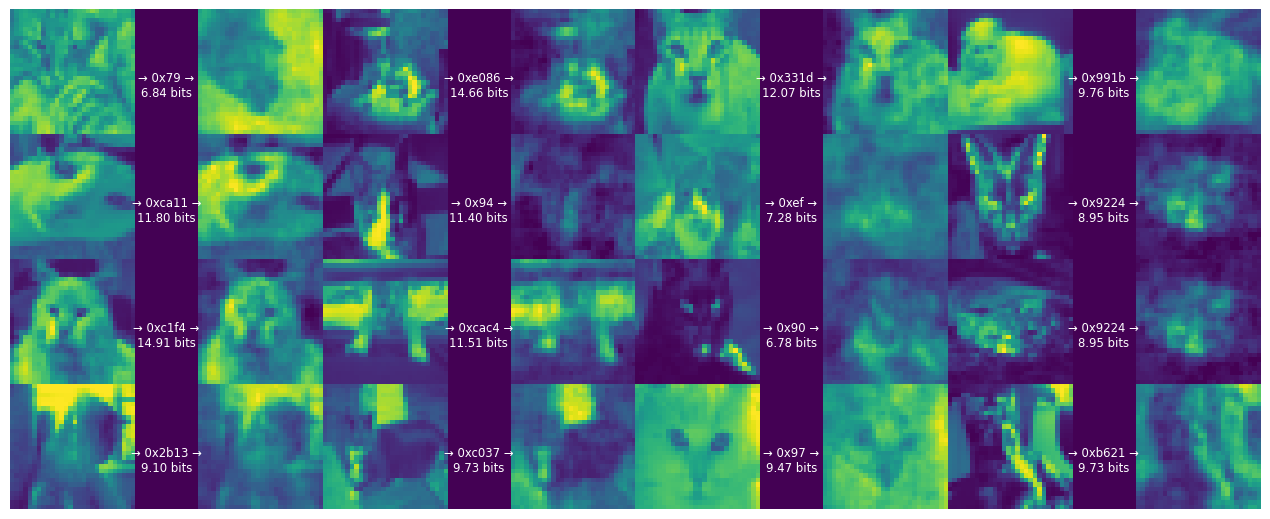

In [69]:
display_digits(originals, strings, entropies, reconstructions)


Note that the length of the encoded string differs from the information content of each digit.

This is because the range coding process works with discrete probabilities, and has a small amount of overhead. So, especially for short strings, the correspondence is only approximate. However, range coding is **asymptotically optimal**: in the limit, the expected bit count will approach the cross entropy (the expected information content), for which the rate term in the training model is an upper bound.

## Use the decoder as a generative model.

If we feed the decoder random bits, this will effectively sample from the distribution that the model learned to represent digits.

First, re-instantiate the compressor/decompressor without a sanity check that would detect if the input string isn't completely decoded.

In [71]:
compressor, decompressor = make_codec(trainer, decode_sanity_check=False)

Now, feed long enough random strings into the decompressor so that it can decode/sample digits from them.

2023-11-15 22:33:08.613224: I tensorflow_compression/cc/kernels/range_coder_kernels.cc:442] RangeDecoder #0 final status was an error
2023-11-15 22:33:08.613595: I tensorflow_compression/cc/kernels/range_coder_kernels.cc:442] RangeDecoder #1 final status was an error
2023-11-15 22:33:08.613650: I tensorflow_compression/cc/kernels/range_coder_kernels.cc:442] RangeDecoder #2 final status was an error
2023-11-15 22:33:08.613682: I tensorflow_compression/cc/kernels/range_coder_kernels.cc:442] RangeDecoder #3 final status was an error
2023-11-15 22:33:08.613709: I tensorflow_compression/cc/kernels/range_coder_kernels.cc:442] RangeDecoder #4 final status was an error
2023-11-15 22:33:08.613737: I tensorflow_compression/cc/kernels/range_coder_kernels.cc:442] RangeDecoder #5 final status was an error
2023-11-15 22:33:08.613764: I tensorflow_compression/cc/kernels/range_coder_kernels.cc:442] RangeDecoder #6 final status was an error
2023-11-15 22:33:08.613790: I tensorflow_compression/cc/kernel

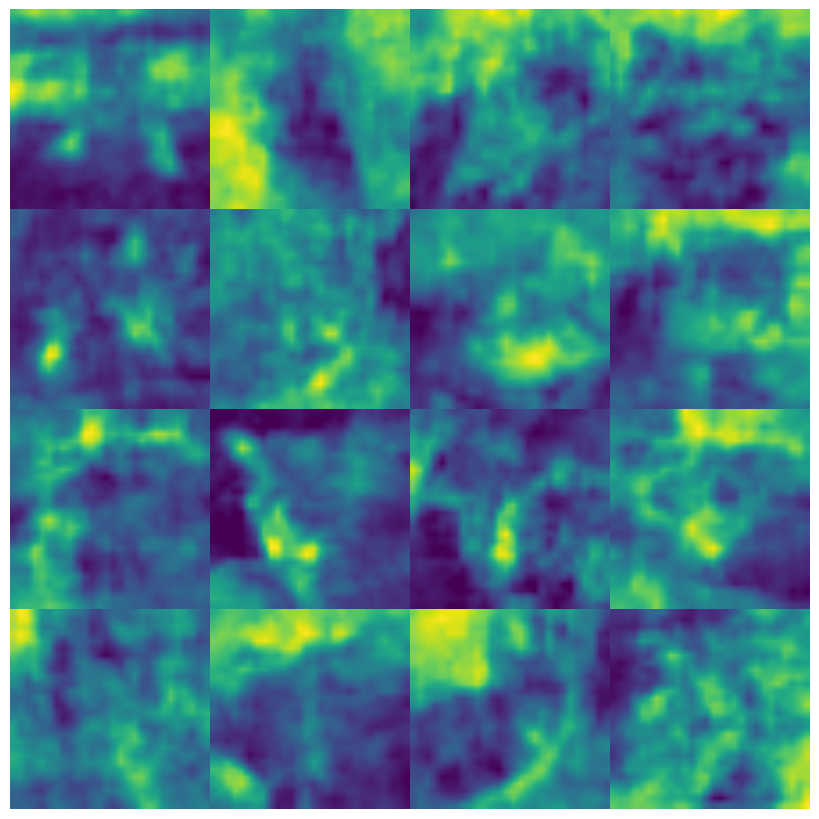

In [72]:
import os

strings = tf.constant([os.urandom(8) for _ in range(16)])
samples = decompressor(strings)

samples = [tf.image.resize(sample, [1024, 1024]) for sample in samples]
samples = tf.convert_to_tensor(samples, dtype=tf.uint8)

fig, axes = plt.subplots(4, 4, sharex=True, sharey=True, figsize=(8, 8))
axes = axes.ravel()
for i in range(len(axes)):
  axes[i].imshow(tf.squeeze(samples[i]))
  axes[i].axis("off")
plt.subplots_adjust(wspace=0, hspace=0, left=0, right=1, bottom=0, top=1)


2023-11-15 22:15:02.547241: I tensorflow_compression/cc/kernels/range_coder_kernels.cc:442] RangeDecoder #0 final status was an error
2023-11-15 22:15:02.547350: I tensorflow_compression/cc/kernels/range_coder_kernels.cc:442] RangeDecoder #1 final status was an error
2023-11-15 22:15:02.547366: I tensorflow_compression/cc/kernels/range_coder_kernels.cc:442] RangeDecoder #2 final status was an error
2023-11-15 22:15:02.547377: I tensorflow_compression/cc/kernels/range_coder_kernels.cc:442] RangeDecoder #3 final status was an error
2023-11-15 22:15:02.547388: I tensorflow_compression/cc/kernels/range_coder_kernels.cc:442] RangeDecoder #4 final status was an error
2023-11-15 22:15:02.547403: I tensorflow_compression/cc/kernels/range_coder_kernels.cc:442] RangeDecoder #5 final status was an error
2023-11-15 22:15:02.547412: I tensorflow_compression/cc/kernels/range_coder_kernels.cc:442] RangeDecoder #6 final status was an error
2023-11-15 22:15:02.547420: I tensorflow_compression/cc/kernel

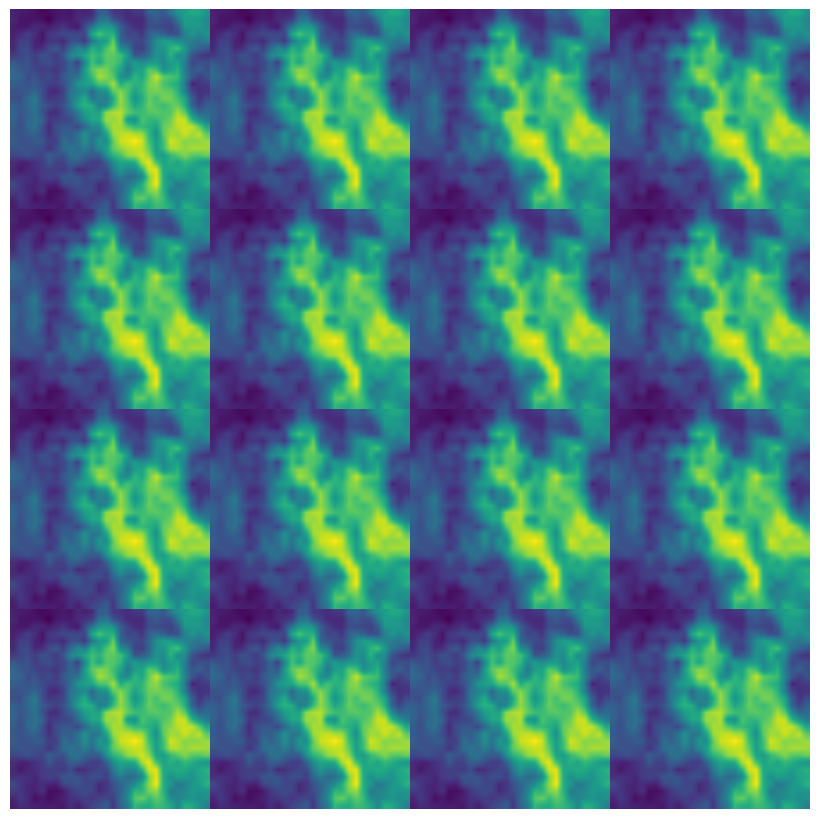

In [58]:
import os

strings = tf.constant(["Yiran".encode('utf-8') for _ in range(16)])
samples = decompressor(strings)


samples = [tf.image.resize(sample, [1024, 1024]) for sample in samples]
samples = tf.convert_to_tensor(samples, dtype=tf.uint8)

fig, axes = plt.subplots(4, 4, sharex=True, sharey=True, figsize=(8, 8))
axes = axes.ravel()
for i in range(len(axes)):
  axes[i].imshow(tf.squeeze(samples[i]))
  axes[i].axis("off")
plt.subplots_adjust(wspace=0, hspace=0, left=0, right=1, bottom=0, top=1)
